In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROJECT_ROOT = Path(r"D:\INSTANT\ML_SV_PROJ")
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "vehicles_cleaned.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (97707, 10)


**skewness**

In [ ]:
skewness = df.select_dtypes(include="number").skew()

skewness.sort_values(
    ascending=False
)

mpg           8.974984
price         2.363865
mileage       1.779719
engineSize    1.410282
tax           0.035928
year         -1.812845
dtype: float64

**Power Transformer (features only)**

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import PowerTransformer

df_transformed = df.copy()

# Yeo-Johnson
yeo_columns = ["mpg", "mileage", "engineSize"]

pt = PowerTransformer(method="yeo-johnson")

df_transformed[yeo_columns] = pt.fit_transform(
    df_transformed[yeo_columns]
)

# Reflection + Log for year
df_transformed["year"] = np.log1p(
    df["year"].max() - df["year"]
)

# Compare before and after
comparison = pd.DataFrame({
    "Before": df.skew(numeric_only=True),
    "After": df_transformed.skew(numeric_only=True)
})

print(comparison)

              Before     After
year       -1.812845 -0.170489
price       2.363865  2.363865
mileage     1.779719 -0.064530
tax         0.035928  0.035928
mpg         8.974984  0.011991
engineSize  1.410282  0.027830


In [ ]:
df = df_transformed.copy()

In [ ]:
print(df.skew(numeric_only=True))

year         -0.170489
price         2.363865
mileage      -0.064530
tax           0.035928
mpg           0.011991
engineSize    0.027830
dtype: float64


# Analysis

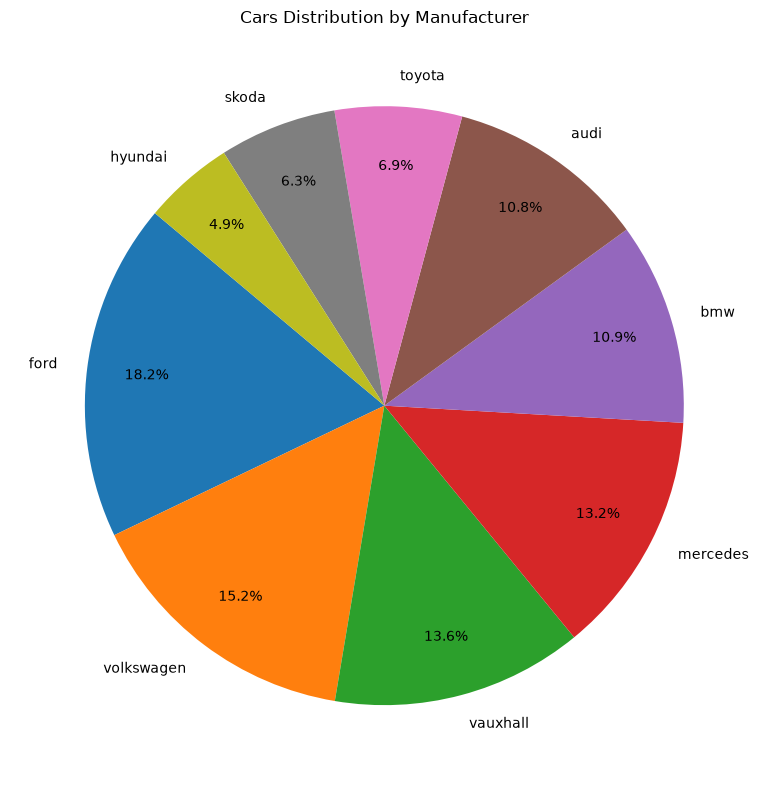

In [ ]:
manufacturer_counts = df["manufacturer"].value_counts()

plt.figure(figsize=(10, 8))

plt.pie(
    manufacturer_counts,
    labels=manufacturer_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    pctdistance=0.8
)

plt.title("Cars Distribution by Manufacturer")
plt.tight_layout()
plt.show()

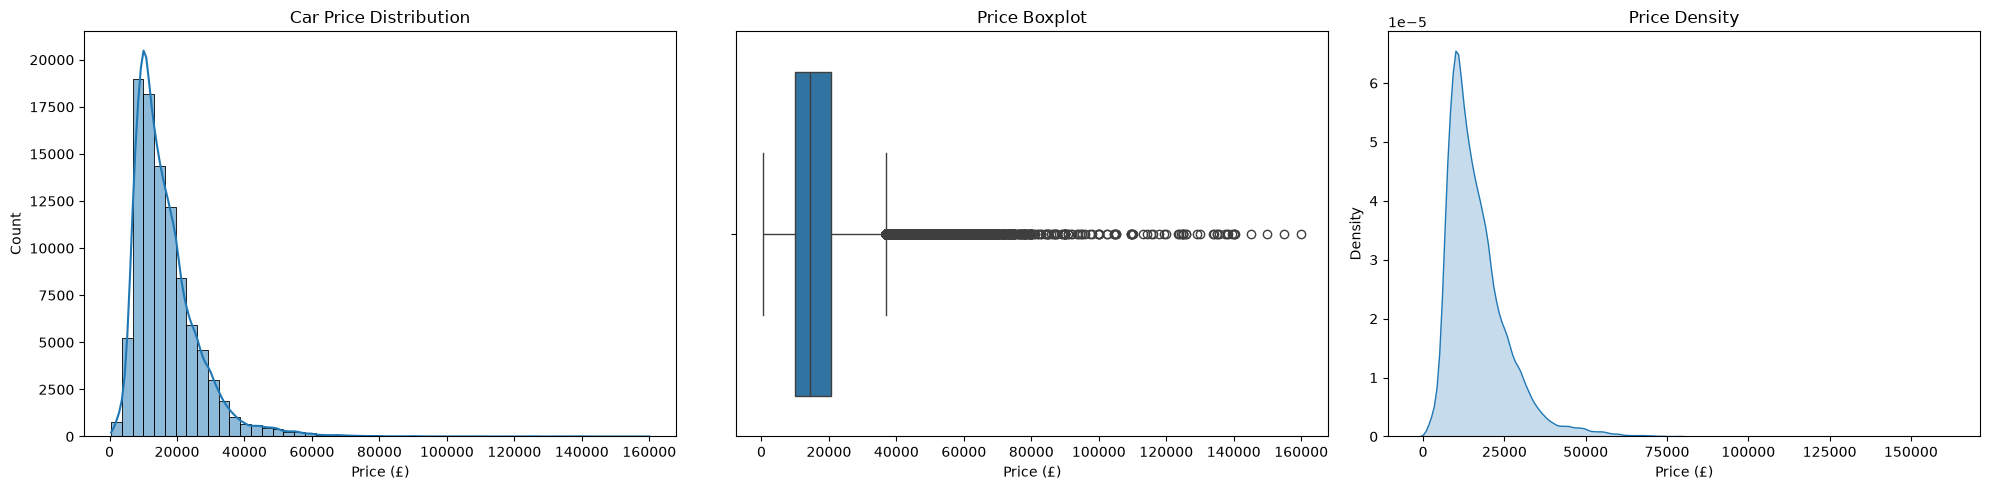

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Histogram + KDE
sns.histplot(data=df, x="price", bins=50, kde=True, ax=axes[0])
axes[0].set_title("Car Price Distribution")
axes[0].set_xlabel("Price (£)")

# 2. Boxplot
sns.boxplot(data=df, x="price", ax=axes[1])
axes[1].set_title("Price Boxplot")
axes[1].set_xlabel("Price (£)")

# 3. KDE
sns.kdeplot(data=df, x="price", fill=True, ax=axes[2])
axes[2].set_title("Price Density")
axes[2].set_xlabel("Price (£)")

plt.tight_layout()
plt.show()

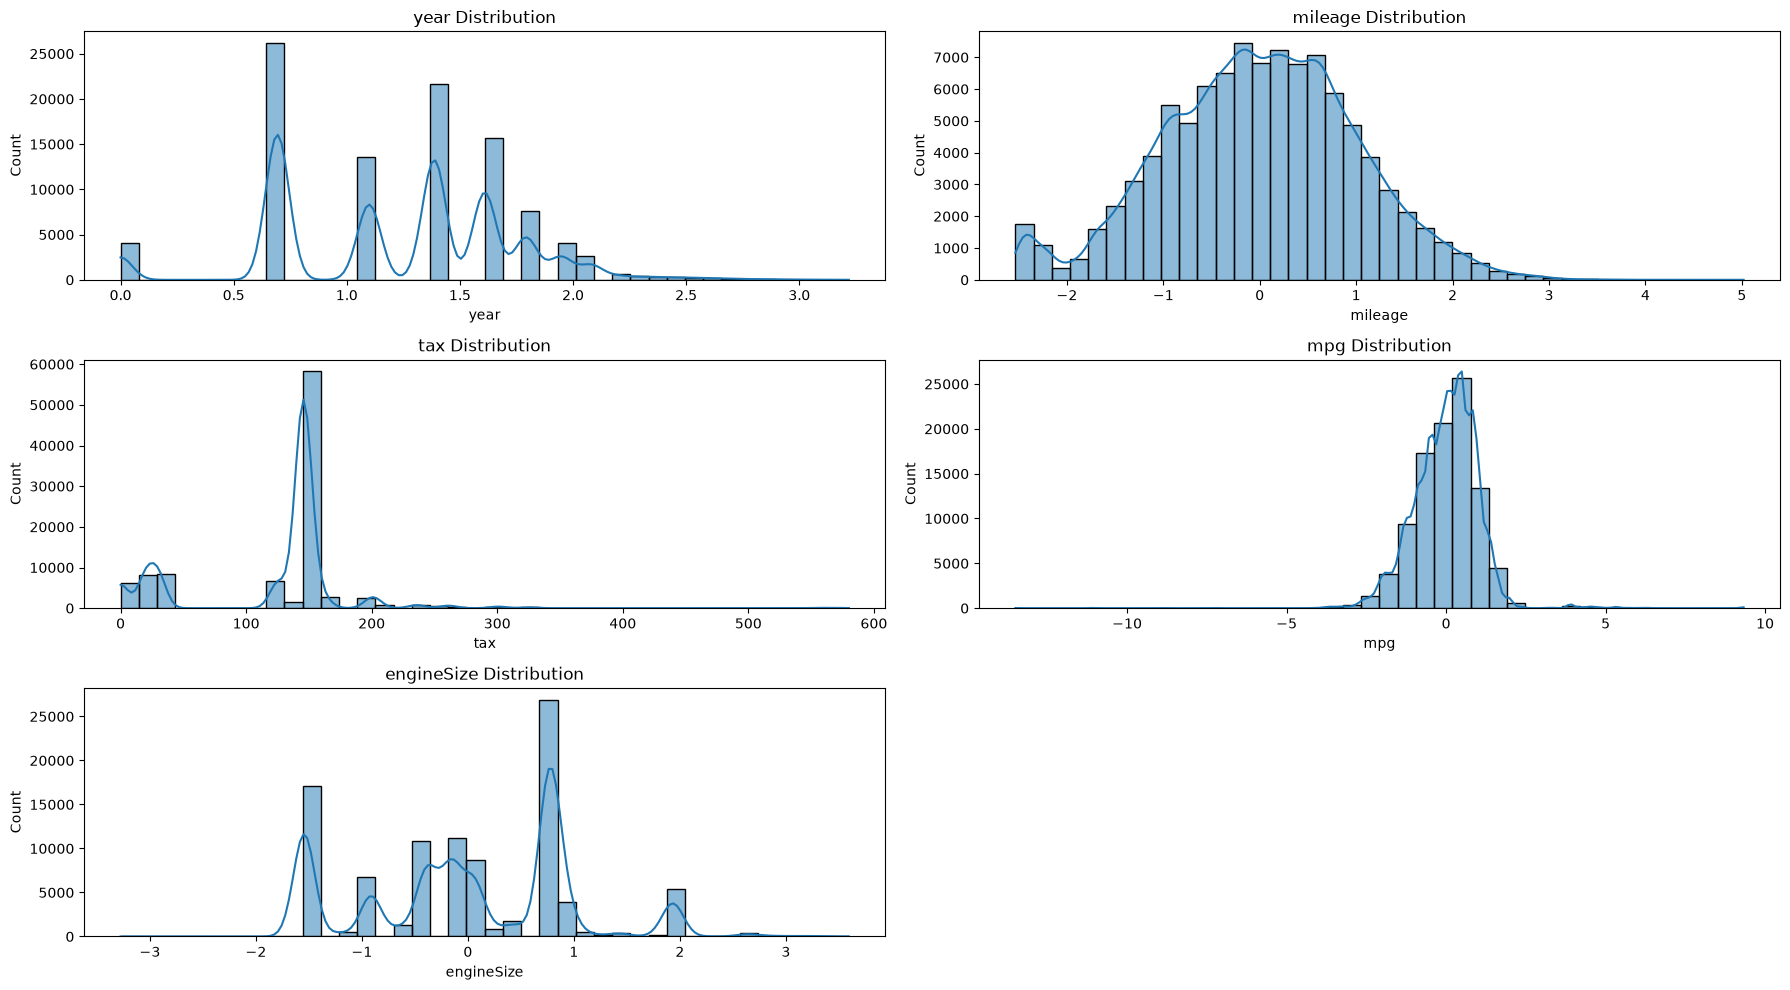

In [ ]:
numerical_features = [
    "year",
    "mileage",
    "tax",
    "mpg",
    "engineSize"
]

fig, axes = plt.subplots(3, 2, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(numerical_features):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=40,
        ax=axes[i]
    )
    axes[i].set_title(f"{col} Distribution")
    axes[i].set_xlabel(col)

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

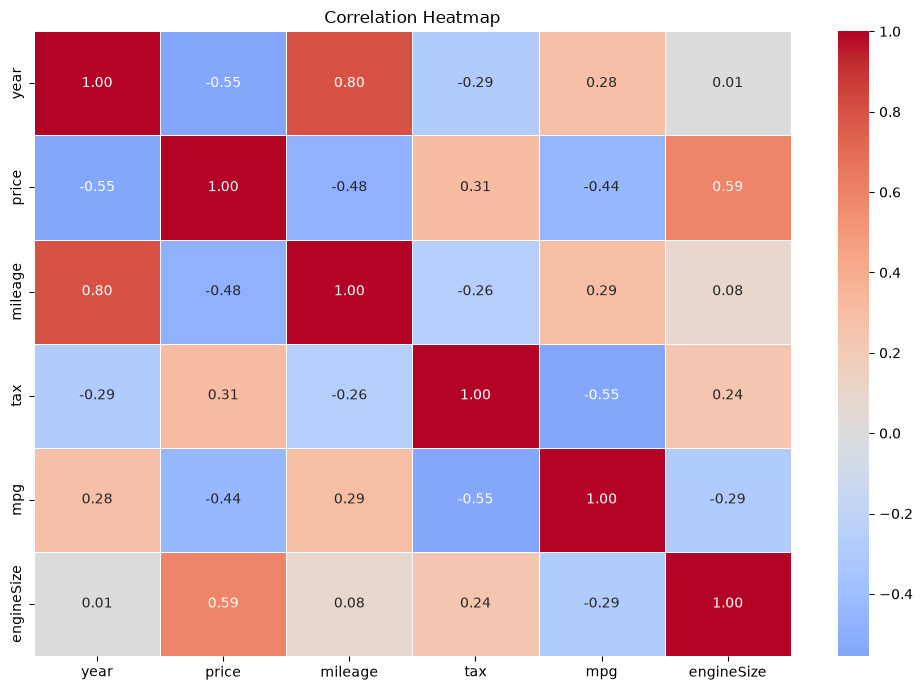

In [ ]:
numerical_df = df.select_dtypes(include="number")

correlation = numerical_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

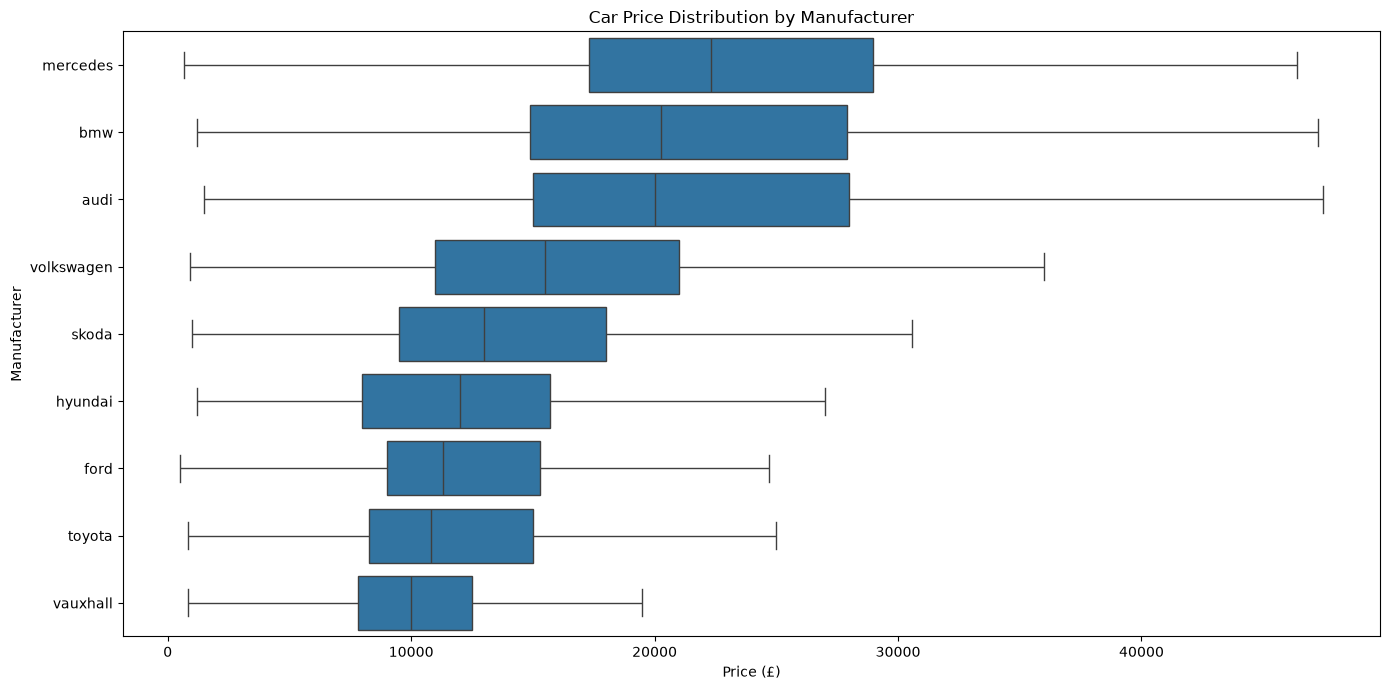

In [ ]:
plt.figure(figsize=(14, 7))

manufacturer_order = (
    df.groupby("manufacturer")["price"]
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=df,
    x="price",
    y="manufacturer",
    order=manufacturer_order,
    showfliers=False
)

plt.title("Car Price Distribution by Manufacturer")
plt.xlabel("Price (£)")
plt.ylabel("Manufacturer")
plt.tight_layout()
plt.show()

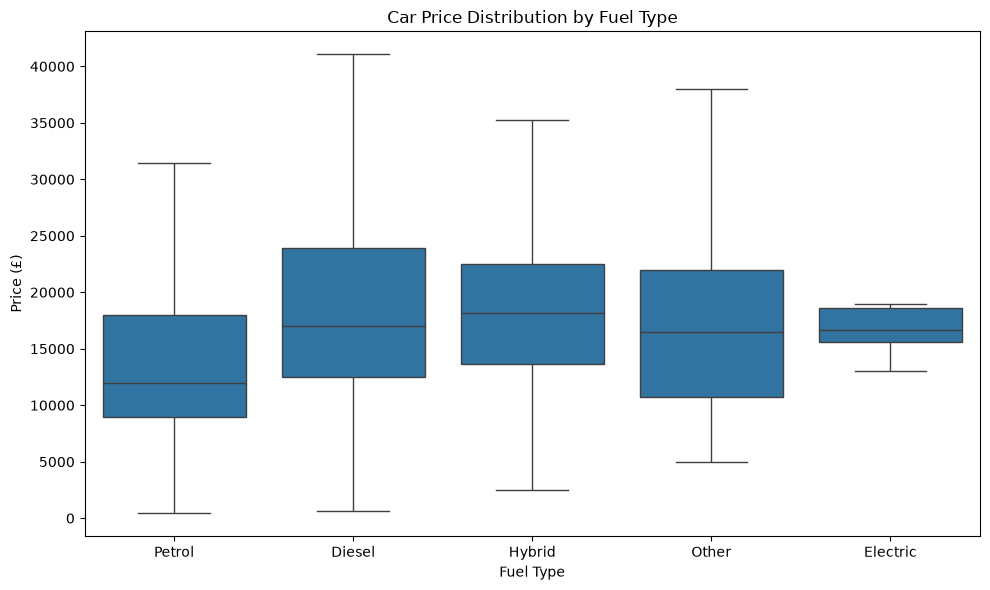

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="fuelType",
    y="price",
    showfliers=False
)

plt.title("Car Price Distribution by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()

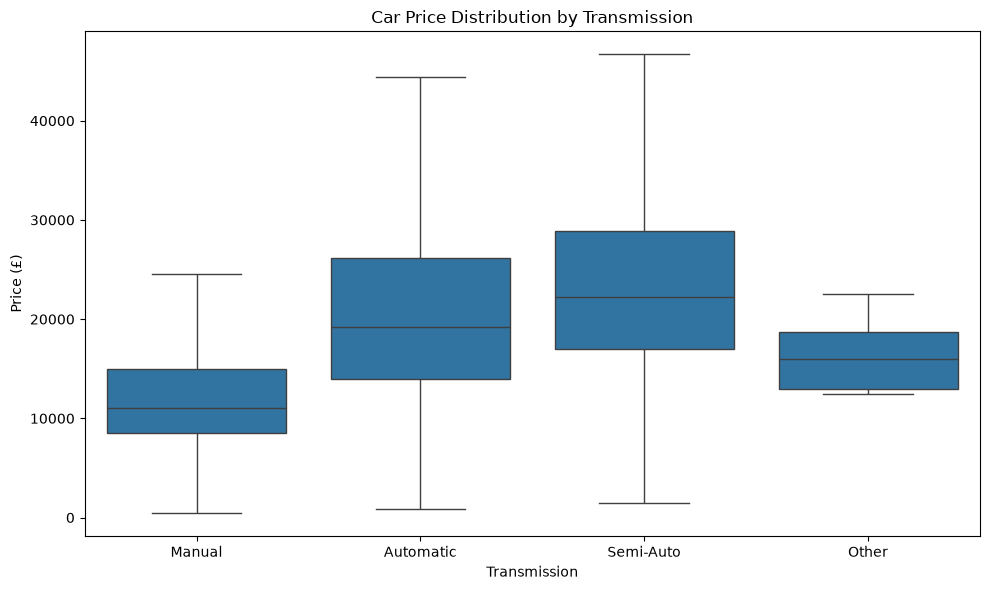

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="transmission",
    y="price",
    showfliers=False
)

plt.title("Car Price Distribution by Transmission")
plt.xlabel("Transmission")
plt.ylabel("Price (£)")

plt.tight_layout()
plt.show()

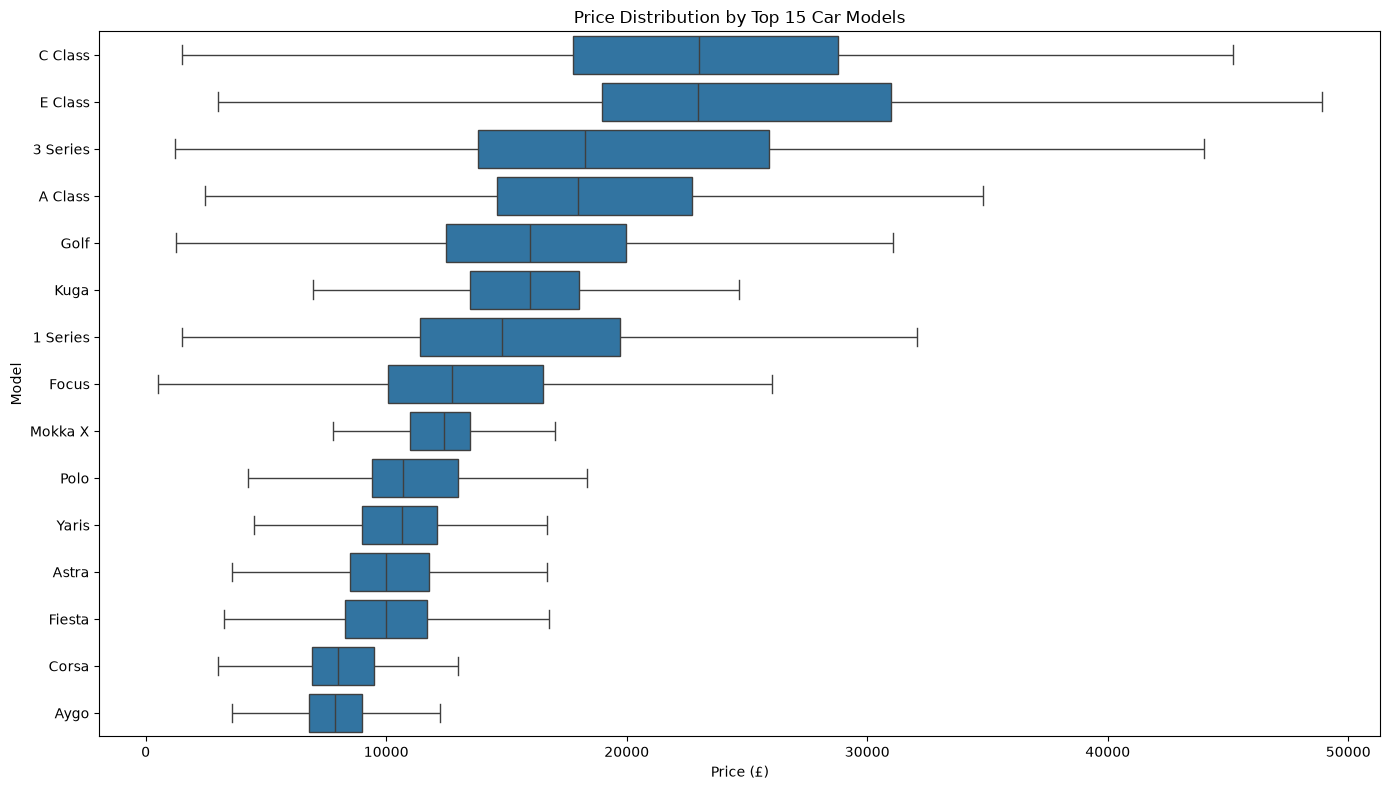

In [ ]:
top_models = df["model"].value_counts().head(15).index

model_order = (
    df[df["model"].isin(top_models)]
    .groupby("model")["price"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df[df["model"].isin(top_models)],
    x="price",
    y="model",
    order=model_order,
    showfliers=False
)

plt.title("Price Distribution by Top 15 Car Models")
plt.xlabel("Price (£)")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

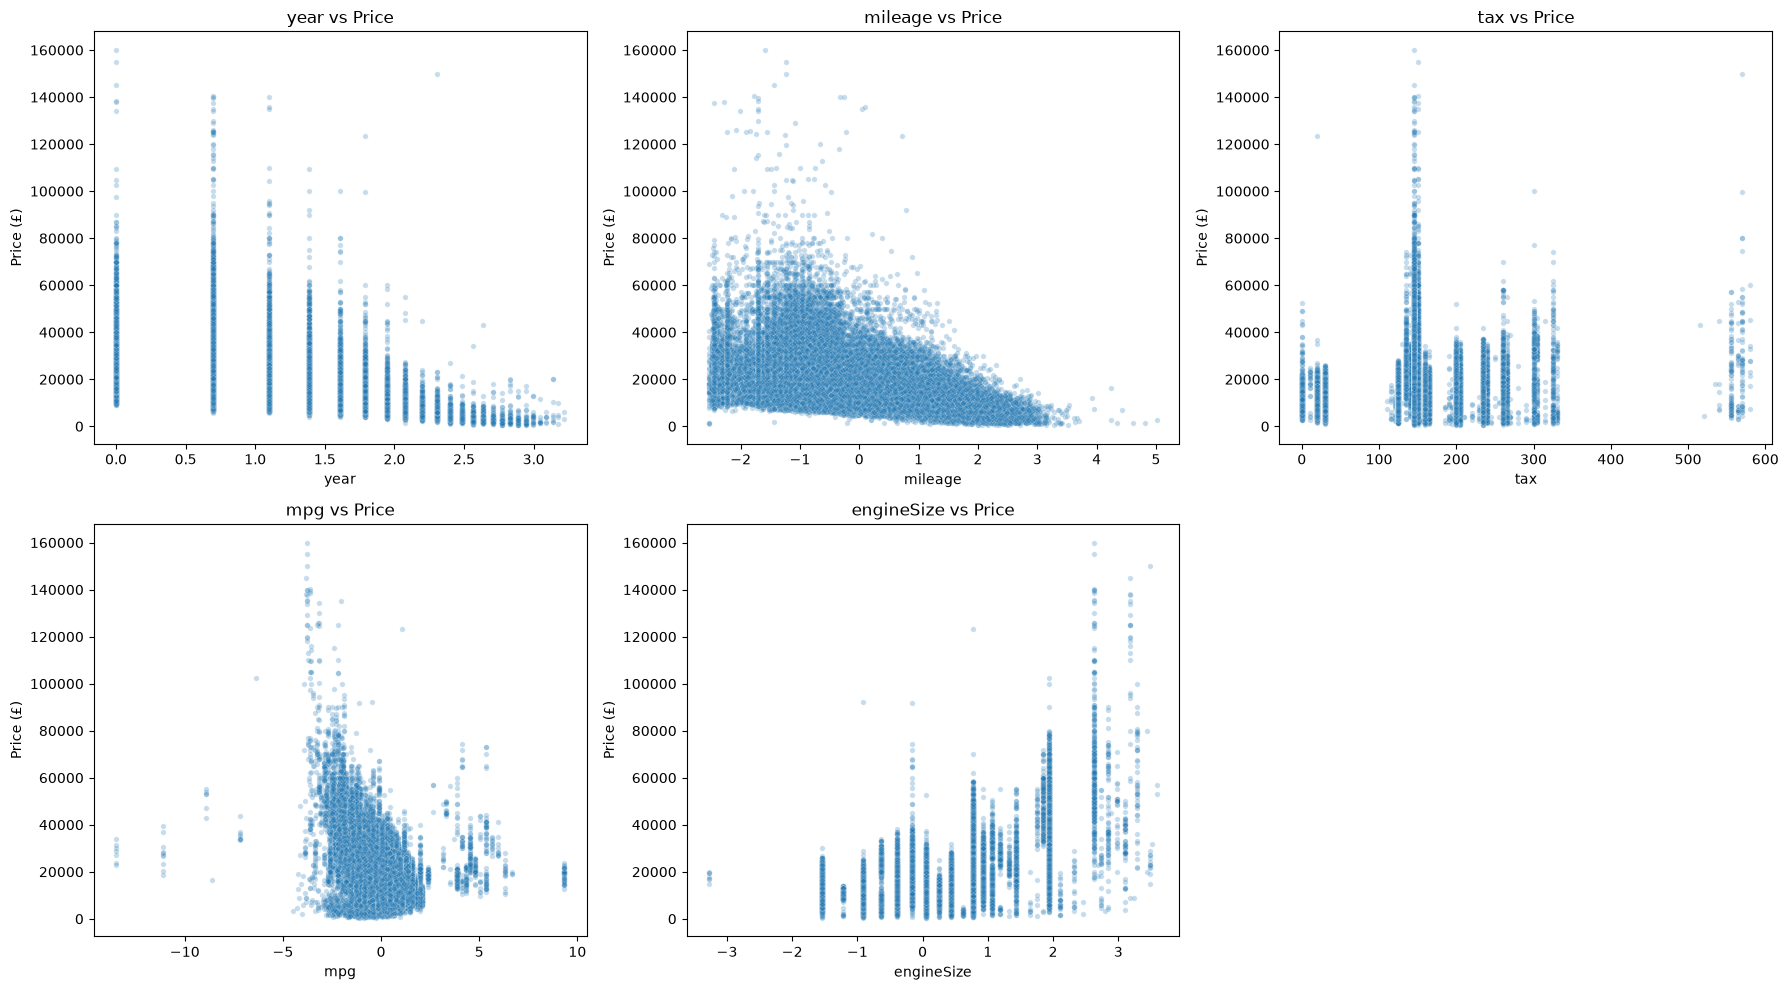

In [ ]:
features = ["year", "mileage", "tax", "mpg", "engineSize"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.scatterplot(
        data=df,
        x=col,
        y="price",
        alpha=0.25,
        s=15,
        ax=axes[i]
    )
    axes[i].set_title(f"{col} vs Price")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Price (£)")

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

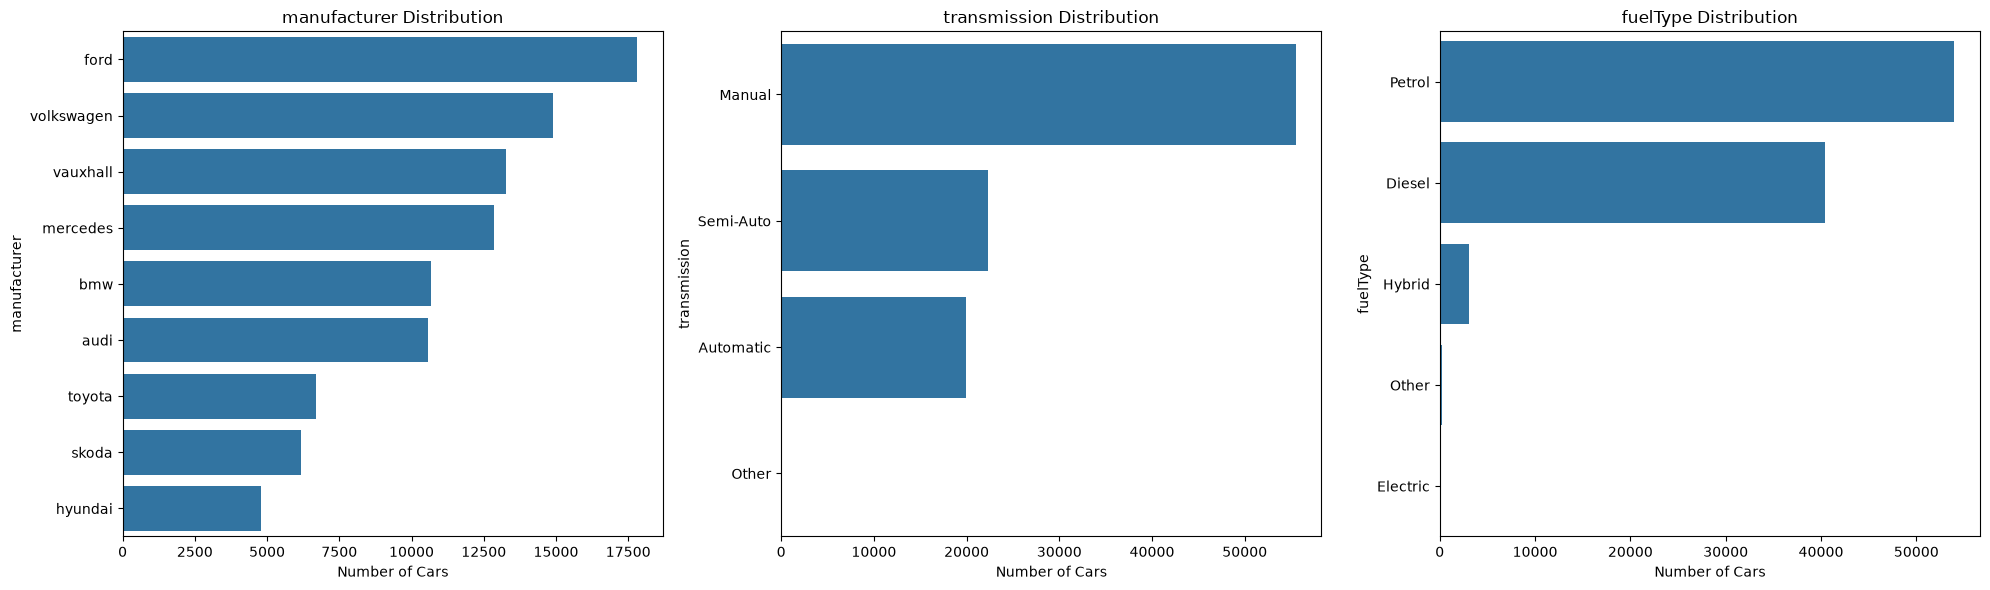

In [ ]:
categorical_features = [
    "manufacturer",
    "transmission",
    "fuelType"
]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, col in enumerate(categorical_features):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        y=col,
        order=order,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} Distribution")
    axes[i].set_xlabel("Number of Cars")
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

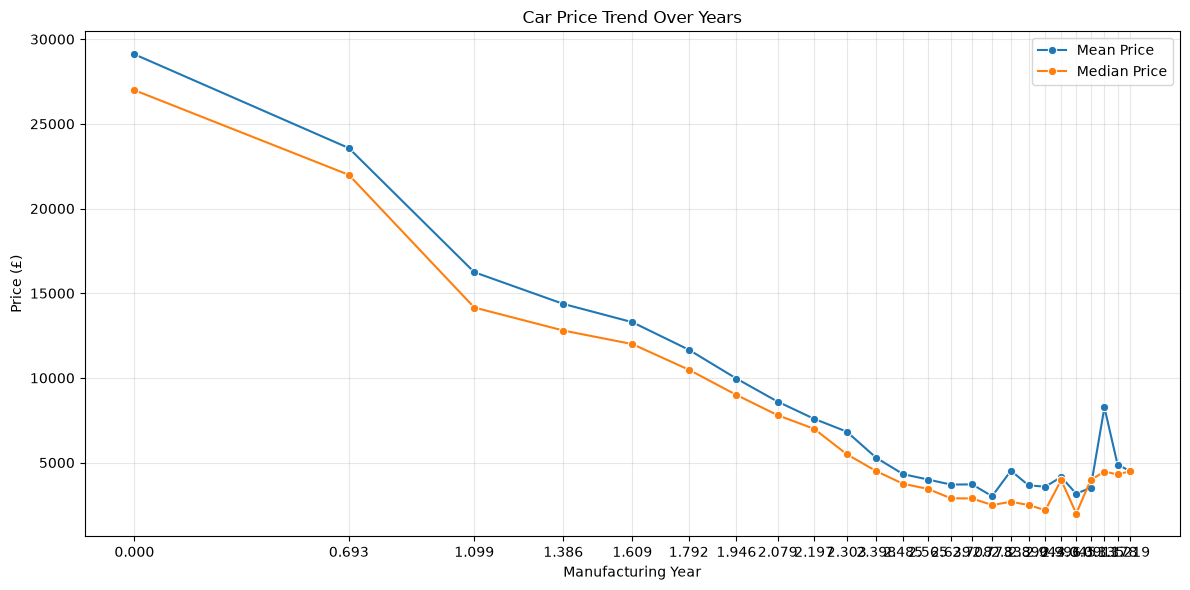

In [ ]:
yearly_prices = df.groupby("year")["price"].agg(
    ["mean", "median"]
).reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_prices,
    x="year",
    y="mean",
    marker="o",
    label="Mean Price"
)

sns.lineplot(
    data=yearly_prices,
    x="year",
    y="median",
    marker="o",
    label="Median Price"
)

plt.title("Car Price Trend Over Years")
plt.xlabel("Manufacturing Year")
plt.ylabel("Price (£)")
plt.xticks(yearly_prices["year"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

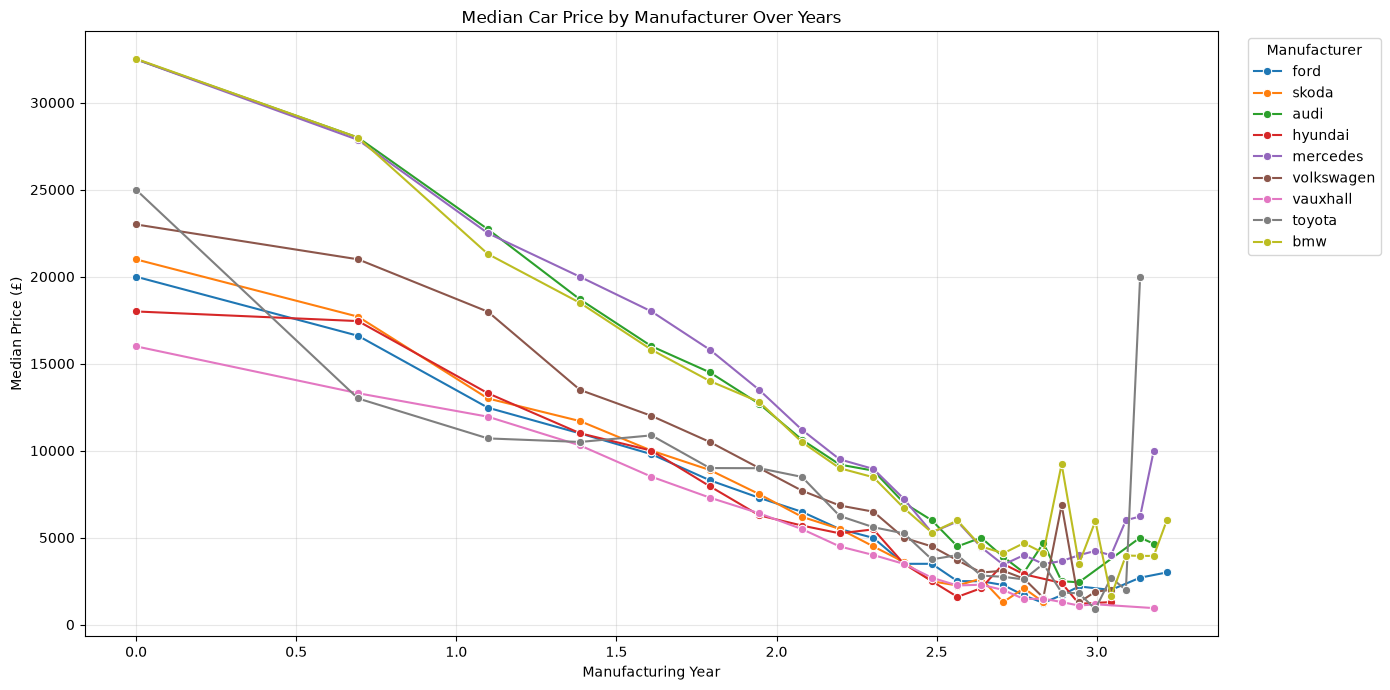

In [ ]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df,
    x="year",
    y="price",
    hue="manufacturer",
    estimator="median",
    errorbar=None,
    marker="o"
)

plt.title("Median Car Price by Manufacturer Over Years")
plt.xlabel("Manufacturing Year")
plt.ylabel("Median Price (£)")
plt.legend(title="Manufacturer", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

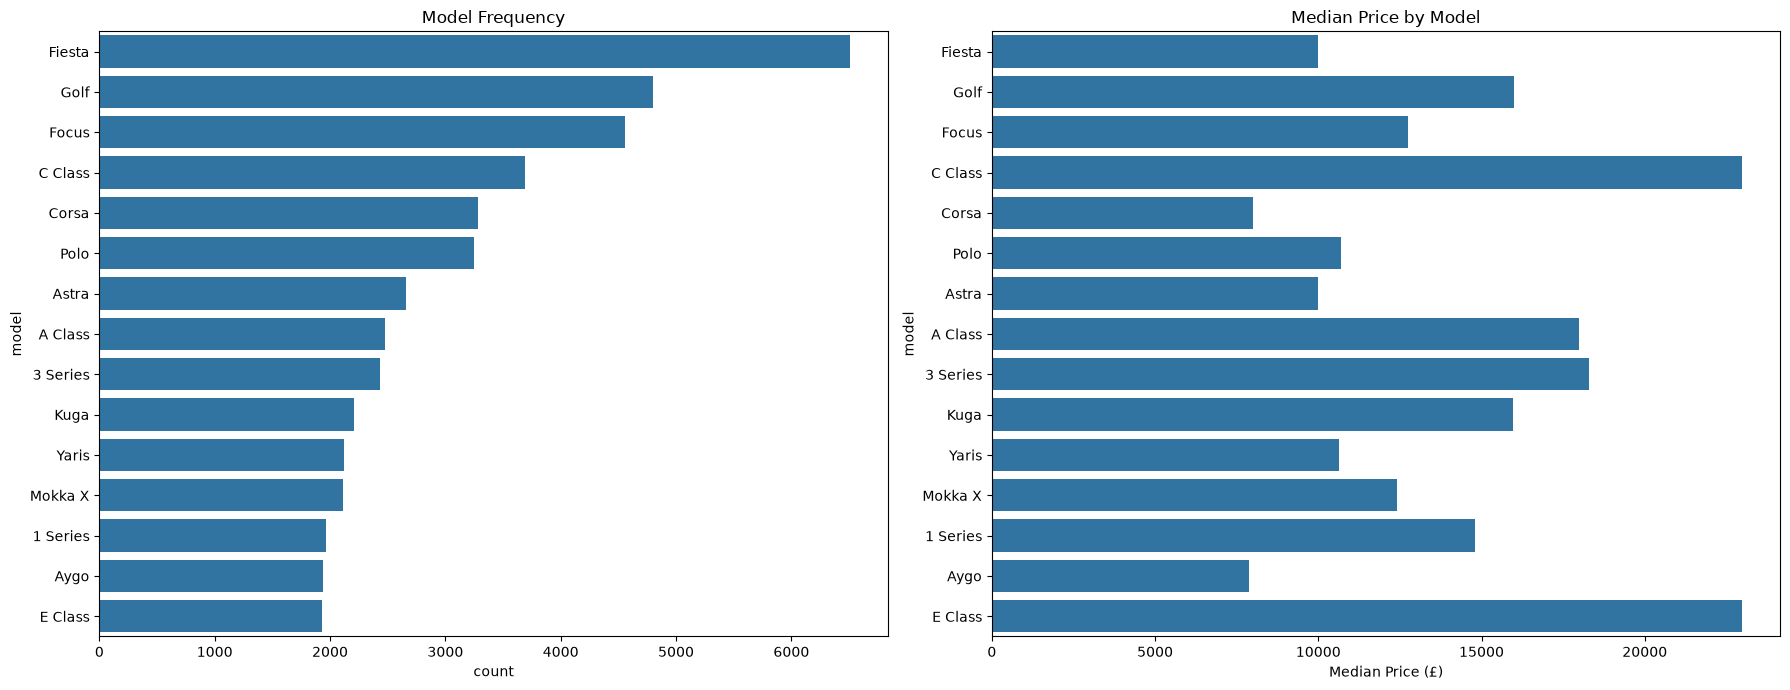

In [ ]:
model_analysis = (
    df.groupby("model")
    .agg(
        count=("model", "size"),
        median_price=("price", "median")
    )
    .reset_index()
)

model_analysis = (
    model_analysis
    .sort_values("count", ascending=False)
    .head(15)
)

model_analysis
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(
    data=model_analysis,
    x="count",
    y="model",
    ax=axes[0]
)
axes[0].set_title("Model Frequency")

sns.barplot(
    data=model_analysis,
    x="median_price",
    y="model",
    ax=axes[1]
)
axes[1].set_title("Median Price by Model")
axes[1].set_xlabel("Median Price (£)")

plt.tight_layout()
plt.show()

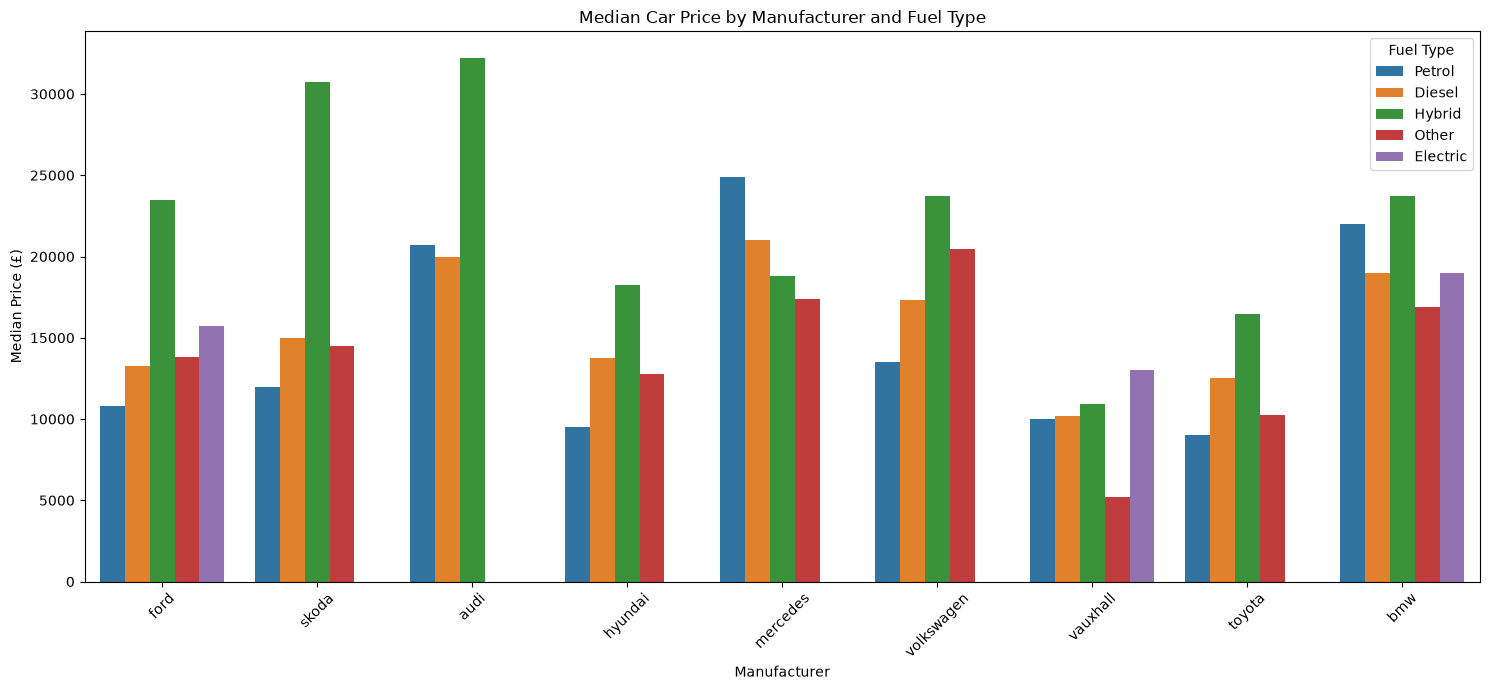

In [ ]:
plt.figure(figsize=(15, 7))

sns.barplot(
    data=df,
    x="manufacturer",
    y="price",
    hue="fuelType",
    estimator="median",
    errorbar=None
)

plt.title("Median Car Price by Manufacturer and Fuel Type")
plt.xlabel("Manufacturer")
plt.ylabel("Median Price (£)")
plt.xticks(rotation=45)
plt.legend(title="Fuel Type")
plt.tight_layout()
plt.show()

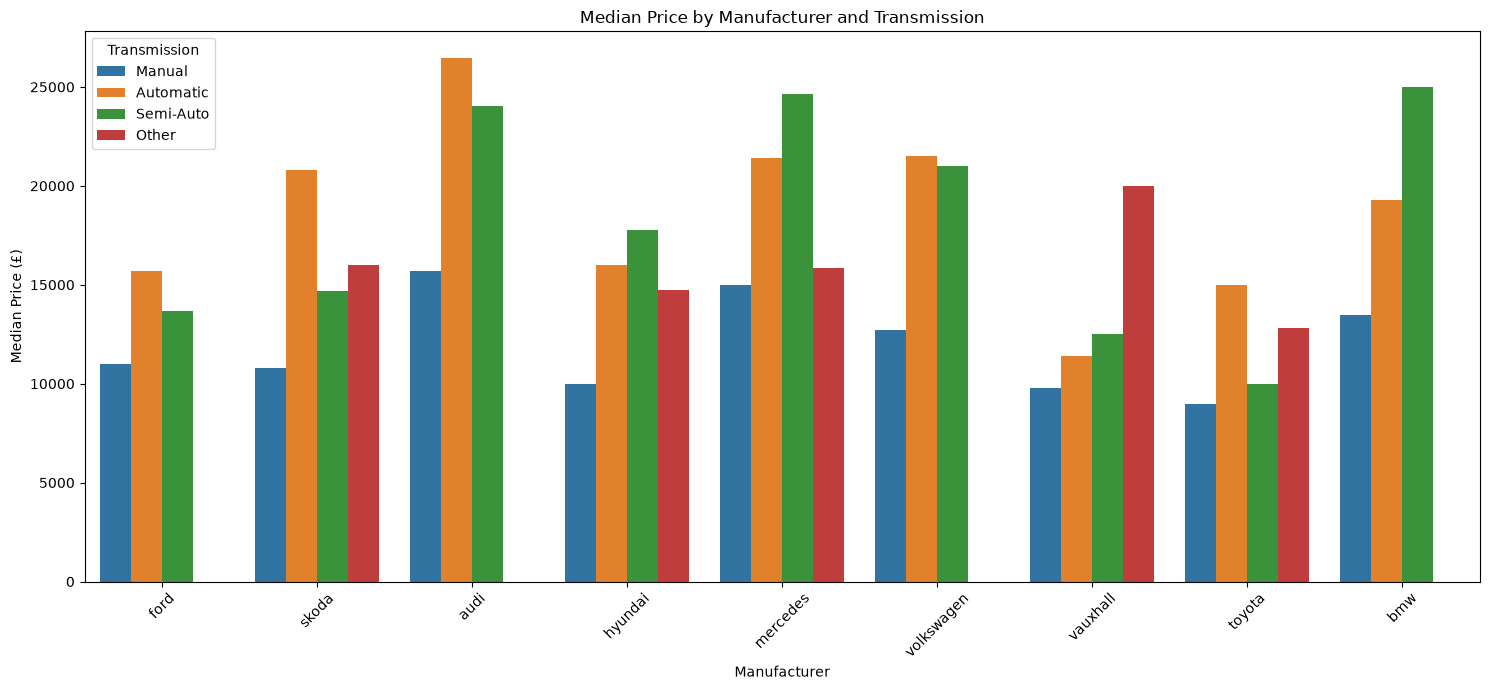

In [ ]:
plt.figure(figsize=(15, 7))

sns.barplot(
    data=df,
    x="manufacturer",
    y="price",
    hue="transmission",
    estimator="median",
    errorbar=None
)

plt.title("Median Price by Manufacturer and Transmission")
plt.xlabel("Manufacturer")
plt.ylabel("Median Price (£)")
plt.xticks(rotation=45)
plt.legend(title="Transmission")
plt.tight_layout()
plt.show()